In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

from pathlib import Path

# Machine learning classifiers
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model training and validation
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    StratifiedKFold
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')

pd.set_option('display.max_columns', 30)

OUTPUT = Path('/kaggle/working')
OUTPUT.mkdir(exist_ok=True)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
files = list(
    Path('/kaggle/input').rglob('cardio_train.csv')
)

if not files:
    raise FileNotFoundError(
        "Please attach the cardiovascular disease dataset."
    )

df = pd.read_csv(
    files[0],
    sep=';'
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0
6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0
7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1
8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0
9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB

Statistical Summary:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000



Missing Values:


id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


Duplicate Records:
0

Unique Values:


id             70000
age             8076
gender             2
height           109
weight           287
ap_hi            153
ap_lo            157
cholesterol        3
gluc               3
smoke              2
alco               2
active             2
cardio             2
dtype: int64

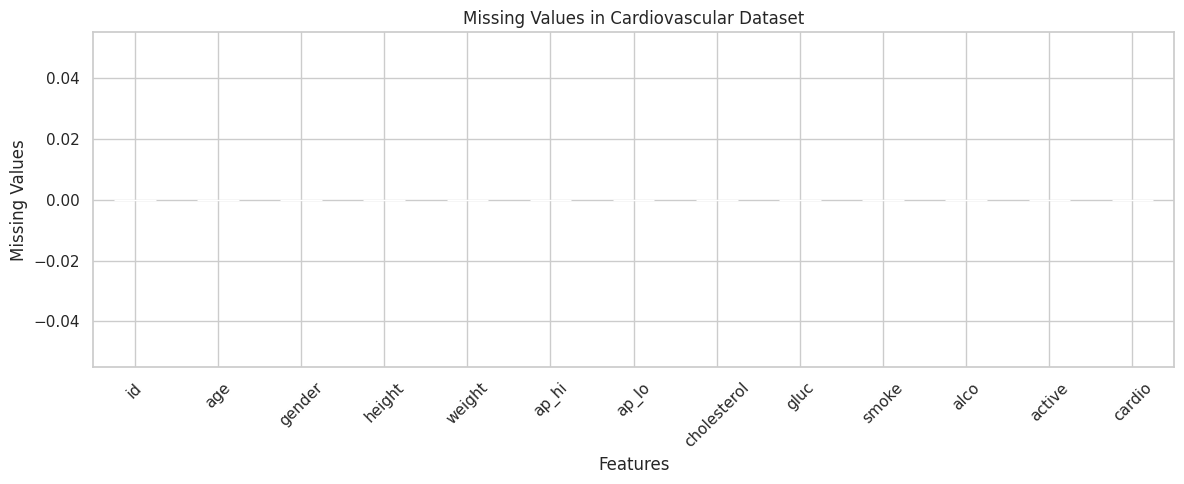

In [4]:
plt.figure(figsize=(12, 5))

df.isnull().sum().plot(
    kind='bar',
    color='#E76F51'
)

plt.title("Missing Values in Cardiovascular Dataset")
plt.xlabel("Features")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT / 'missing_values.png',
    dpi=150
)

plt.show()

In [5]:
clean = df.copy()

# Remove patient identifier
clean = clean.drop(columns=['id'])

# Convert features to numeric
for col in clean.columns:
    clean[col] = pd.to_numeric(
        clean[col],
        errors='coerce'
    )

# Remove duplicate observations
clean = clean.drop_duplicates()

# Remove missing or invalid target values
clean = clean[
    clean['cardio'].isin([0, 1])
].copy()

# Convert age from days to years
clean['age_years'] = (
    clean['age'] / 365.25
)

clean = clean.drop(columns=['age'])

# Broad data quality bounds
bounds = {
    'age_years': (18, 100),
    'height': (100, 250),
    'weight': (25, 300),
    'ap_hi': (60, 300),
    'ap_lo': (30, 200)
}

for col, (lower, upper) in bounds.items():

    valid = (
        clean[col].between(lower, upper) |
        clean[col].isna()
    )

    clean = clean[valid]

# Systolic pressure must exceed diastolic pressure
clean = clean[
    (clean['ap_hi'] > clean['ap_lo']) |
    clean['ap_hi'].isna() |
    clean['ap_lo'].isna()
]

# Validate categorical features
valid_categories = {
    'gender': [1, 2],
    'cholesterol': [1, 2, 3],
    'gluc': [1, 2, 3],
    'smoke': [0, 1],
    'alco': [0, 1],
    'active': [0, 1]
}

for col, allowed in valid_categories.items():

    clean.loc[
        ~clean[col].isin(allowed),
        col
    ] = np.nan

clean['cardio'] = clean['cardio'].astype(int)

clean = clean.drop_duplicates()
clean = clean.reset_index(drop=True)

print("Original records:", len(df))
print("Cleaned records:", len(clean))
print("Removed records:", len(df) - len(clean))

display(clean.head())

Original records: 70000
Cleaned records: 68624
Removed records: 1376


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,2.0,168,62.0,110,80,1.0,1.0,0.0,0.0,1.0,0,50.357290
1,1.0,156,85.0,140,90,3.0,1.0,0.0,0.0,1.0,1,55.381246
2,1.0,165,64.0,130,70,3.0,1.0,0.0,0.0,0.0,1,51.627652
3,2.0,169,82.0,150,100,1.0,1.0,0.0,0.0,1.0,1,48.249144
4,1.0,156,56.0,100,60,1.0,1.0,0.0,0.0,0.0,0,47.841205


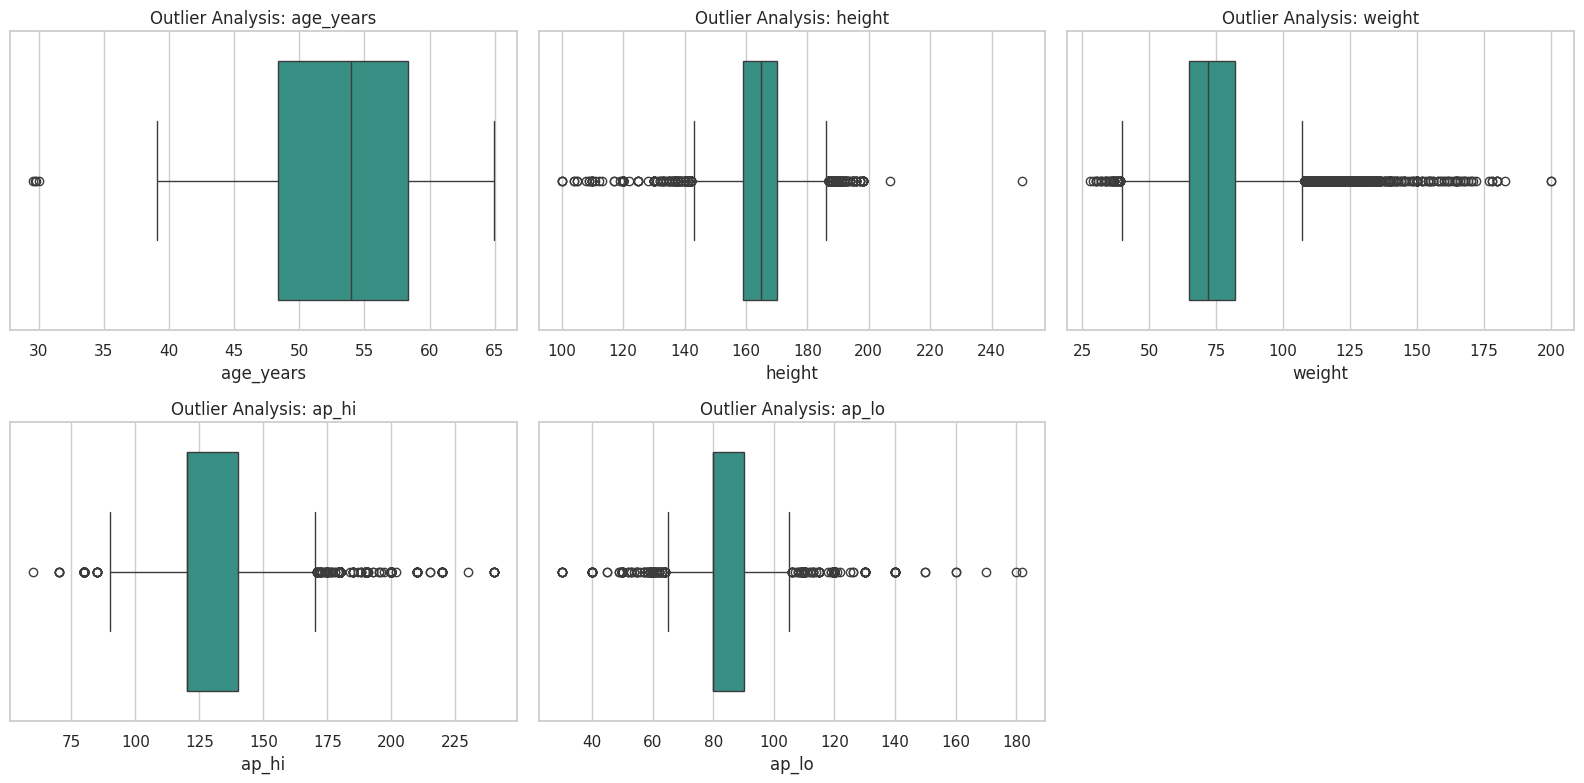

In [6]:
numeric_columns = [
    'age_years',
    'height',
    'weight',
    'ap_hi',
    'ap_lo'
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8)
)

for ax, col in zip(
    axes.flatten(),
    numeric_columns
):

    sns.boxplot(
        x=clean[col],
        ax=ax,
        color='#2A9D8F'
    )

    ax.set_title(f"Outlier Analysis: {col}")

axes.flatten()[-1].axis('off')

plt.tight_layout()

plt.savefig(
    OUTPUT / 'outlier_analysis.png',
    dpi=150
)

plt.show()

In [7]:
outlier_report = []

for col in numeric_columns:

    Q1 = clean[col].quantile(0.25)
    Q3 = clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (clean[col] < lower) |
        (clean[col] > upper)
    ).sum()

    outlier_report.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Potential Outliers': count
    })

outlier_report = pd.DataFrame(outlier_report)

display(outlier_report.round(2))

,Feature,Lower Bound,Upper Bound,Potential Outliers
0,age_years,33.29,73.44,4
1,height,142.50,186.50,479
2,weight,39.50,107.50,1737
3,ap_hi,90.00,170.00,1011
4,ap_lo,65.00,105.00,3508


In [8]:
def add_features(data):

    data = data.copy()

    data['BMI'] = (
        data['weight'] /
        (data['height'] / 100) ** 2
    )

    data['PulsePressure'] = (
        data['ap_hi'] - data['ap_lo']
    )

    return data


clean = add_features(clean)

display(clean.head())

print("Updated dataset shape:", clean.shape)

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,BMI,PulsePressure
0,2.0,168,62.0,110,80,1.0,1.0,0.0,0.0,1.0,0,50.357290,21.967120,30
1,1.0,156,85.0,140,90,3.0,1.0,0.0,0.0,1.0,1,55.381246,34.927679,50
2,1.0,165,64.0,130,70,3.0,1.0,0.0,0.0,0.0,1,51.627652,23.507805,60
3,2.0,169,82.0,150,100,1.0,1.0,0.0,0.0,1.0,1,48.249144,28.710479,50
4,1.0,156,56.0,100,60,1.0,1.0,0.0,0.0,0.0,0,47.841205,23.011177,40


Updated dataset shape: (68624, 14)


cardio
0    34668
1    33956
Name: count, dtype: int64

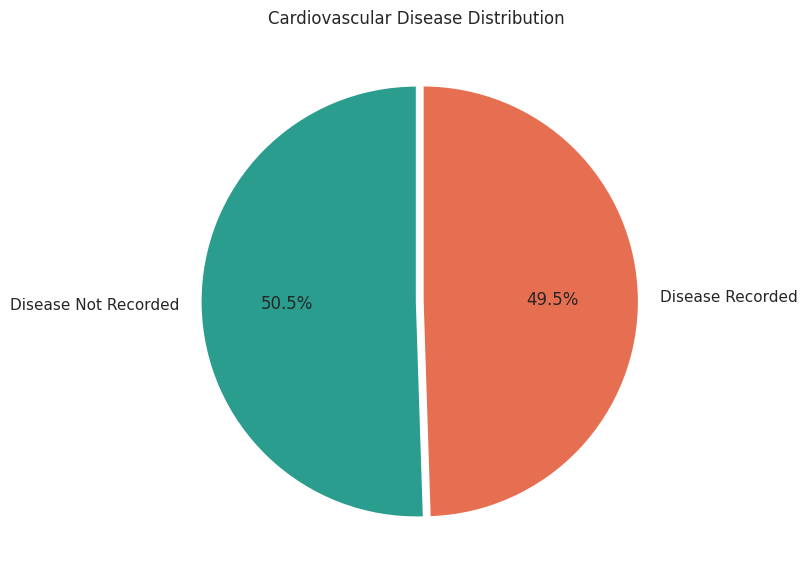

In [9]:
counts = clean['cardio'].value_counts().reindex(
    [0, 1],
    fill_value=0
)

display(counts)

plt.figure(figsize=(7, 7))

plt.pie(
    counts.values,
    labels=[
        'Disease Not Recorded',
        'Disease Recorded'
    ],
    autopct='%1.1f%%',
    colors=['#2A9D8F', '#E76F51'],
    startangle=90,
    explode=[0, 0.03]
)

plt.title("Cardiovascular Disease Distribution")

plt.savefig(
    OUTPUT / 'disease_distribution.png',
    dpi=150
)

plt.show()

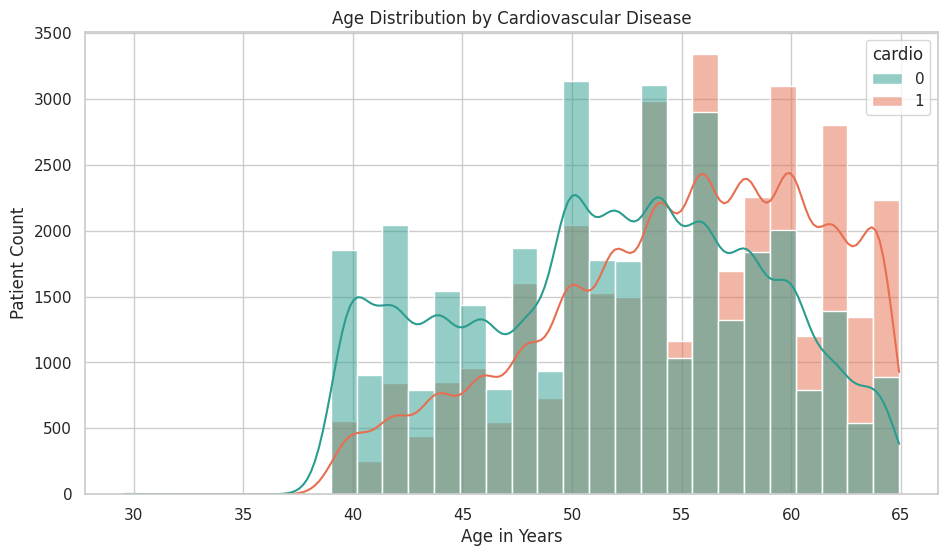

In [10]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=clean,
    x='age_years',
    hue='cardio',
    bins=30,
    kde=True,
    palette=['#2A9D8F', '#E76F51']
)

plt.title("Age Distribution by Cardiovascular Disease")
plt.xlabel("Age in Years")
plt.ylabel("Patient Count")

plt.savefig(
    OUTPUT / 'age_analysis.png',
    dpi=150
)

plt.show()

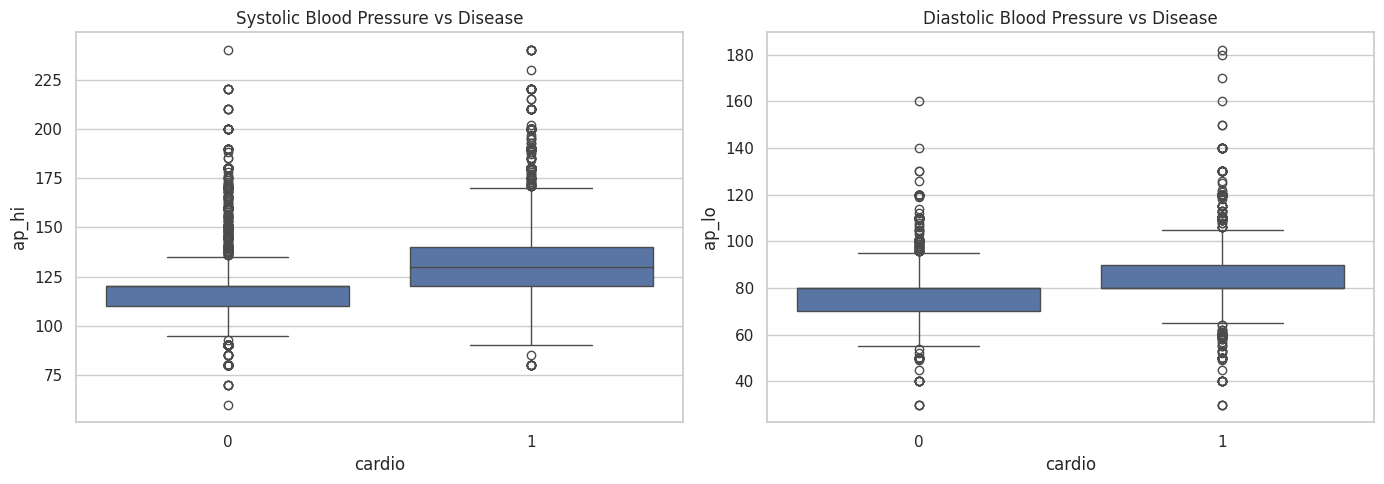

In [11]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.boxplot(
    data=clean,
    x='cardio',
    y='ap_hi',
    ax=axes[0]
)

axes[0].set_title(
    "Systolic Blood Pressure vs Disease"
)

sns.boxplot(
    data=clean,
    x='cardio',
    y='ap_lo',
    ax=axes[1]
)

axes[1].set_title(
    "Diastolic Blood Pressure vs Disease"
)

plt.tight_layout()

plt.savefig(
    OUTPUT / 'blood_pressure_analysis.png',
    dpi=150
)

plt.show()

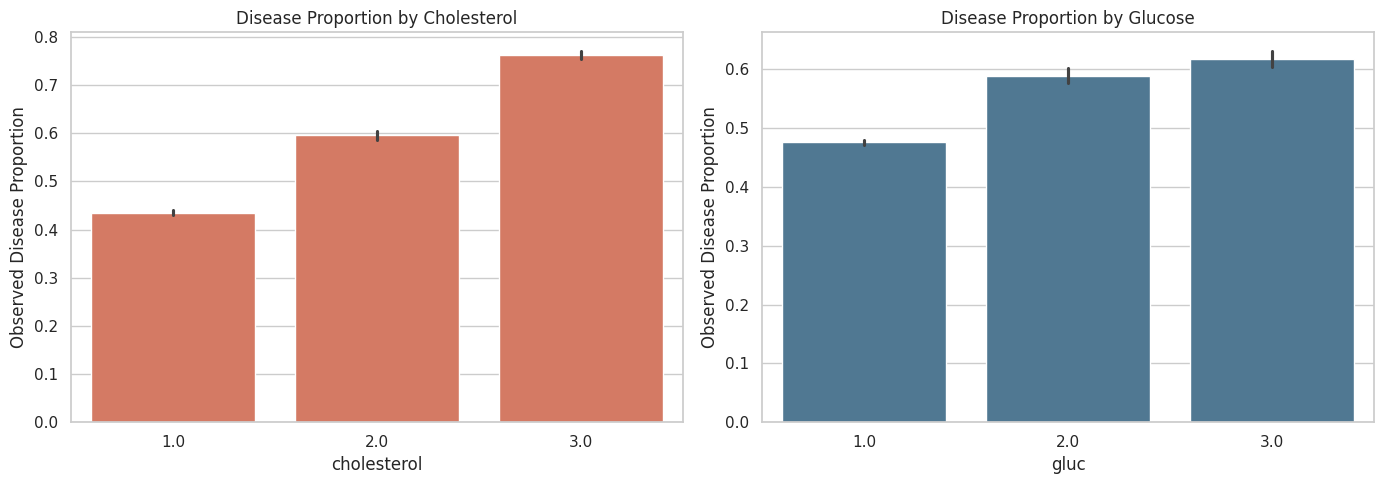

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.barplot(
    data=clean,
    x='cholesterol',
    y='cardio',
    ax=axes[0],
    color='#E76F51'
)

axes[0].set_title(
    "Disease Proportion by Cholesterol"
)

axes[0].set_ylabel("Observed Disease Proportion")

sns.barplot(
    data=clean,
    x='gluc',
    y='cardio',
    ax=axes[1],
    color='#457B9D'
)

axes[1].set_title(
    "Disease Proportion by Glucose"
)

axes[1].set_ylabel("Observed Disease Proportion")

plt.tight_layout()

plt.savefig(
    OUTPUT / 'cholesterol_glucose_analysis.png',
    dpi=150
)

plt.show()

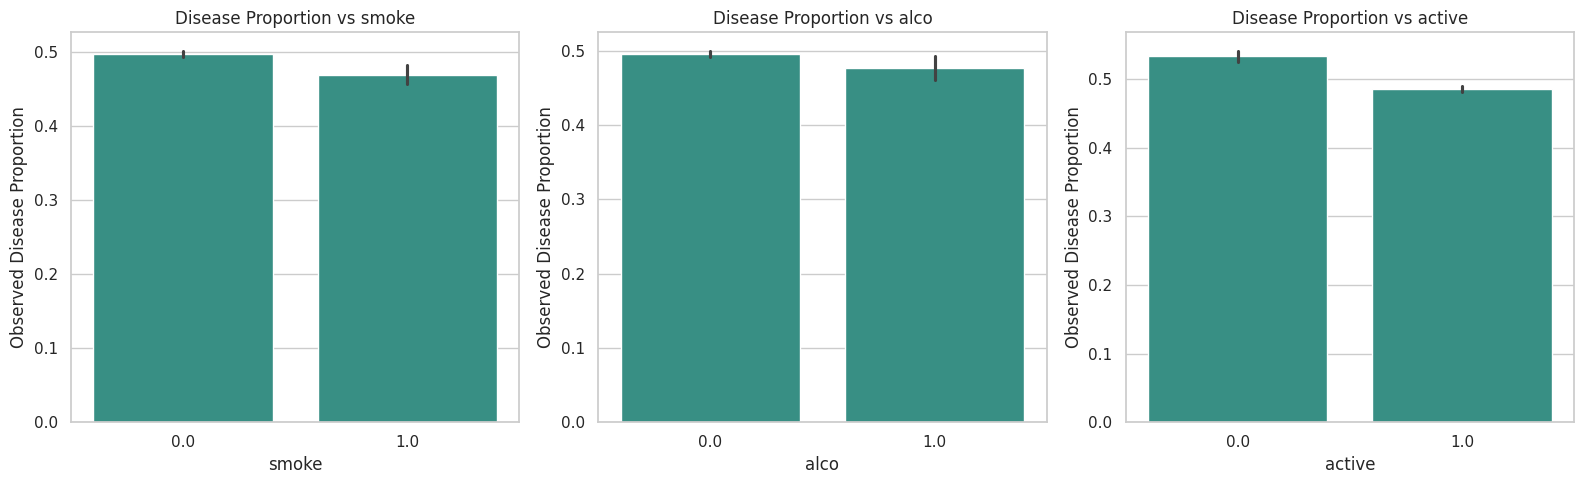

In [13]:
lifestyle_features = [
    'smoke',
    'alco',
    'active'
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, col in zip(axes, lifestyle_features):

    sns.barplot(
        data=clean,
        x=col,
        y='cardio',
        ax=ax,
        color='#2A9D8F'
    )

    ax.set_title(
        f"Disease Proportion vs {col}"
    )

    ax.set_ylabel("Observed Disease Proportion")

plt.tight_layout()

plt.savefig(
    OUTPUT / 'lifestyle_analysis.png',
    dpi=150
)

plt.show()

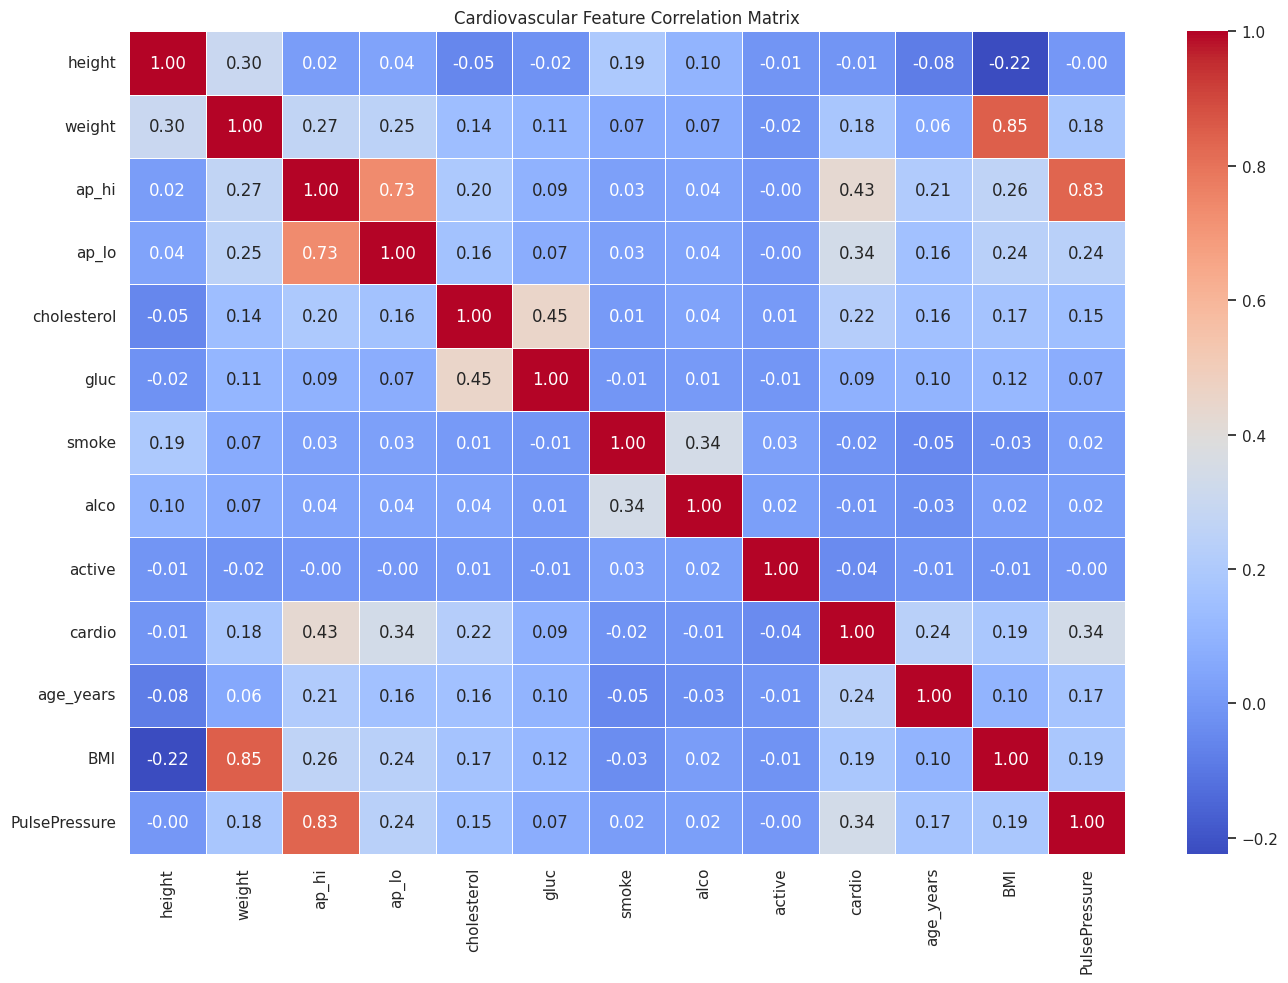

In [14]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    clean.drop(columns=['gender']).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Cardiovascular Feature Correlation Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT / 'correlation_heatmap.png',
    dpi=150
)

plt.show()

In [15]:
X = clean.drop(columns=['cardio'])

y = clean['cardio']

feature_columns = X.columns.tolist()

print("Input Features:")
print(feature_columns)

print("\nFeature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

Input Features:
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'BMI', 'PulsePressure']

Feature Dataset Shape: (68624, 13)
Target Dataset Shape: (68624,)


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (54899, 13)
Testing Features: (13725, 13)

Training Target Distribution:
cardio
0    0.505182
1    0.494818
Name: proportion, dtype: float64

Testing Target Distribution:
cardio
0    0.505209
1    0.494791
Name: proportion, dtype: float64


In [17]:
continuous_features = [
    'age_years',
    'height',
    'weight',
    'ap_hi',
    'ap_lo',
    'BMI',
    'PulsePressure'
]

nominal_features = [
    'gender'
]

ordinal_binary_features = [
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active'
]


def make_preprocessor():

    numeric_pipeline = Pipeline([
        (
            'imputer',
            SimpleImputer(strategy='median')
        ),
        (
            'scaler',
            StandardScaler()
        )
    ])

    nominal_pipeline = Pipeline([
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        ),
        (
            'encoder',
            OneHotEncoder(
                drop='if_binary',
                handle_unknown='ignore',
                sparse_output=False
            )
        )
    ])

    categorical_pipeline = Pipeline([
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        )
    ])

    return ColumnTransformer([
        (
            'numeric',
            numeric_pipeline,
            continuous_features
        ),
        (
            'nominal',
            nominal_pipeline,
            nominal_features
        ),
        (
            'categorical',
            categorical_pipeline,
            ordinal_binary_features
        )
    ])


print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [18]:
dt_model = Pipeline([
    (
        'preprocessing',
        make_preprocessor()
    ),
    (
        'classifier',
        DecisionTreeClassifier(
            criterion='entropy',
            max_depth=8,
            min_samples_leaf=20,
            random_state=42
        )
    )
])

print("Decision Tree model configured!")

Decision Tree model configured!


In [19]:
nb_model = Pipeline([
    (
        'preprocessing',
        make_preprocessor()
    ),
    (
        'classifier',
        GaussianNB()
    )
])

print("Naive Bayes model configured!")

Naive Bayes model configured!


In [20]:
knn_model = Pipeline([
    (
        'preprocessing',
        make_preprocessor()
    ),
    (
        'classifier',
        KNeighborsClassifier(
            n_neighbors=15,
            weights='distance',
            metric='euclidean',
            n_jobs=-1
        )
    )
])

print("K-Nearest Neighbor model configured!")

K-Nearest Neighbor model configured!


In [21]:
ann_model = Pipeline([
    (
        'preprocessing',
        make_preprocessor()
    ),
    (
        'classifier',
        MLPClassifier(
            hidden_layer_sizes=(64, 32, 16),
            activation='relu',
            solver='adam',
            learning_rate_init=0.001,
            batch_size=128,
            max_iter=200,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        )
    )
])

print("Artificial Neural Network configured!")

Artificial Neural Network configured!


In [22]:
models = {
    'Decision Tree': dt_model,
    'Naive Bayes': nb_model,
    'KNN': knn_model,
    'ANN': ann_model
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

cv_results = []

for name, model in models.items():

    print(f"Cross-validating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score='raise'
    )

    cv_results.append({
        'Model': name,
        'CV Accuracy': scores[
            'test_accuracy'
        ].mean(),
        'CV Precision': scores[
            'test_precision'
        ].mean(),
        'CV Recall': scores[
            'test_recall'
        ].mean(),
        'CV F1': scores[
            'test_f1'
        ].mean(),
        'CV ROC AUC': scores[
            'test_roc_auc'
        ].mean(),
        'F1 Std': scores[
            'test_f1'
        ].std()
    })

cv_results = pd.DataFrame(cv_results)

display(
    cv_results.sort_values(
        'CV F1',
        ascending=False
    ).round(4)
)

Cross-validating Decision Tree...
Cross-validating Naive Bayes...
Cross-validating KNN...
Cross-validating ANN...


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,F1 Std
3,ANN,0.7341,0.7573,0.6816,0.7173,0.8002,0.0028
0,Decision Tree,0.7313,0.7545,0.6777,0.7139,0.7942,0.0043
2,KNN,0.7178,0.7246,0.6934,0.7086,0.7751,0.0053
1,Naive Bayes,0.7163,0.7673,0.6124,0.6811,0.7810,0.0065


In [23]:
best_model_name = cv_results.loc[
    cv_results['CV F1'].idxmax(),
    'Model'
]

print(
    "Selected Model Based on Cross-Validation:",
    best_model_name
)

Selected Model Based on Cross-Validation: ANN


In [24]:
trained_models = {}

predictions = {}

probabilities = {}

training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.time()

    model.fit(X_train, y_train)

    training_times[name] = (
        time.time() - start
    )

    trained_models[name] = model

    predictions[name] = model.predict(
        X_test
    )

    probabilities[name] = model.predict_proba(
        X_test
    )[:, 1]

    print(f"{name} trained successfully!")

    print(
        "Training Time:",
        round(training_times[name], 2),
        "seconds"
    )


Training Decision Tree...
Decision Tree trained successfully!
Training Time: 0.29 seconds

Training Naive Bayes...
Naive Bayes trained successfully!
Training Time: 0.09 seconds

Training KNN...
KNN trained successfully!
Training Time: 0.2 seconds

Training ANN...
ANN trained successfully!
Training Time: 7.7 seconds


In [25]:
results = []

for name in trained_models:

    pred = predictions[name]
    prob = probabilities[name]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(
            y_test, pred
        ),
        'Precision': precision_score(
            y_test, pred,
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred,
            zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, pred,
            zero_division=0
        ),
        'ROC AUC': roc_auc_score(
            y_test, prob
        ),
        'Training Time': training_times[name]
    })

results = pd.DataFrame(results)

results = results.sort_values(
    'F1 Score',
    ascending=False
)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time
3,ANN,0.7277,0.7459,0.6818,0.7124,0.7937,7.6973
0,Decision Tree,0.7238,0.7518,0.6594,0.7026,0.7847,0.2868
2,KNN,0.7089,0.7157,0.6828,0.6989,0.7621,0.2017
1,Naive Bayes,0.7081,0.7578,0.6027,0.6714,0.7762,0.0877


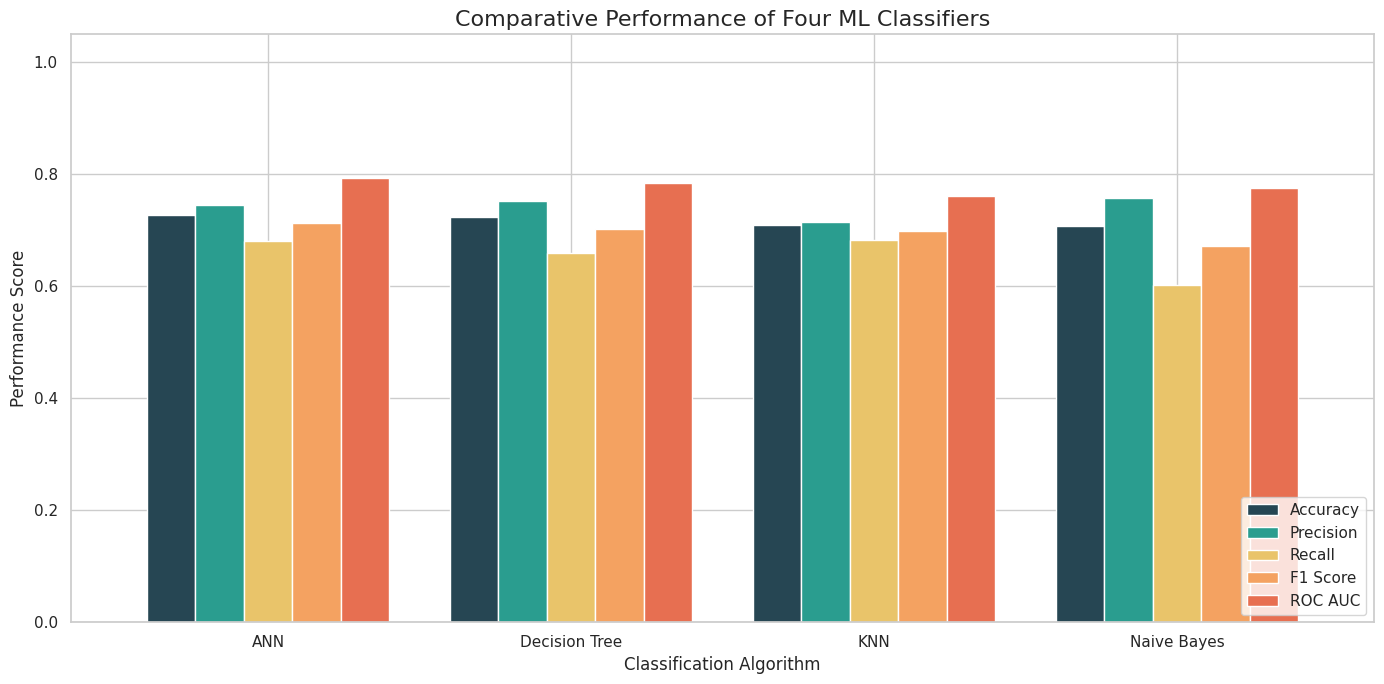

In [26]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC AUC'
]

results.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8,
    color=[
        '#264653',
        '#2A9D8F',
        '#E9C46A',
        '#F4A261',
        '#E76F51'
    ]
)

plt.title(
    "Comparative Performance of Four ML Classifiers",
    fontsize=16
)

plt.ylabel("Performance Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig(
    OUTPUT / 'model_comparison.png',
    dpi=200
)

plt.show()

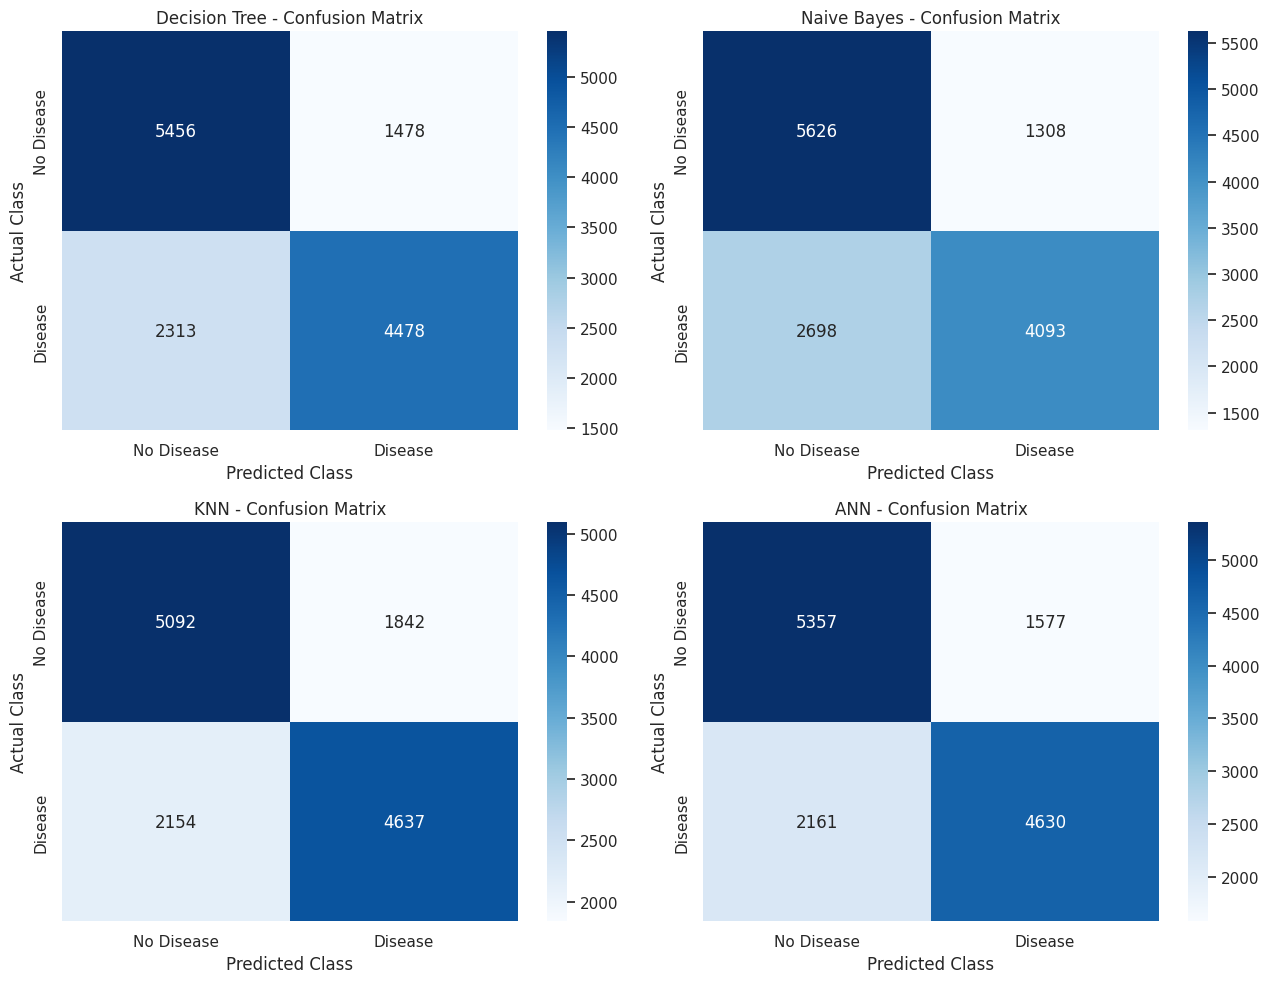

In [27]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for ax, name in zip(
    axes.flatten(),
    trained_models.keys()
):

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=[
            'No Disease',
            'Disease'
        ],
        yticklabels=[
            'No Disease',
            'Disease'
        ]
    )

    ax.set_title(
        f"{name} - Confusion Matrix"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    OUTPUT / 'confusion_matrices.png',
    dpi=200
)

plt.show()

In [28]:
for name in trained_models:

    print("\n" + "=" * 50)

    print(f"{name} Classification Report")

    print("=" * 50)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                'No Disease',
                'Disease'
            ],
            zero_division=0
        )
    )


Decision Tree Classification Report
              precision    recall  f1-score   support

  No Disease       0.70      0.79      0.74      6934
     Disease       0.75      0.66      0.70      6791

    accuracy                           0.72     13725
   macro avg       0.73      0.72      0.72     13725
weighted avg       0.73      0.72      0.72     13725


Naive Bayes Classification Report
              precision    recall  f1-score   support

  No Disease       0.68      0.81      0.74      6934
     Disease       0.76      0.60      0.67      6791

    accuracy                           0.71     13725
   macro avg       0.72      0.71      0.70     13725
weighted avg       0.72      0.71      0.70     13725


KNN Classification Report
              precision    recall  f1-score   support

  No Disease       0.70      0.73      0.72      6934
     Disease       0.72      0.68      0.70      6791

    accuracy                           0.71     13725
   macro avg       0.71      

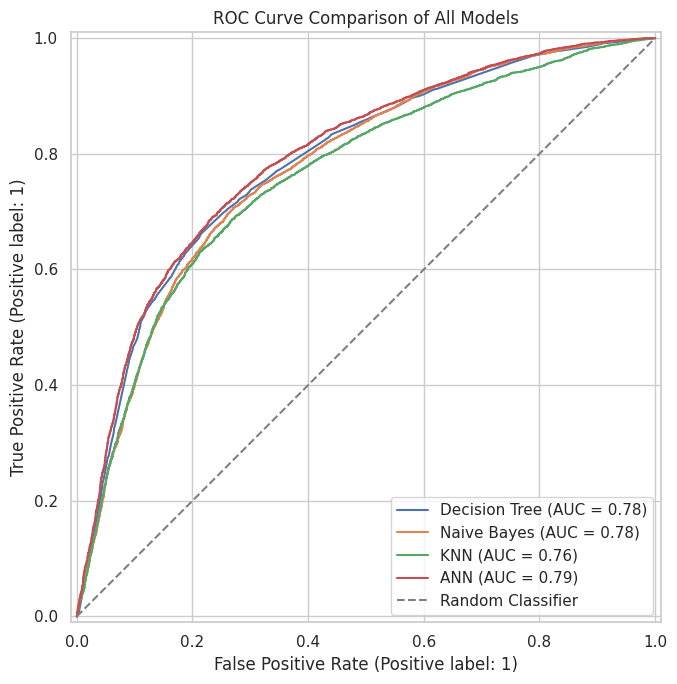

In [29]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

for name in trained_models:

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison of All Models")
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig(
    OUTPUT / 'roc_curve_comparison.png',
    dpi=200
)

plt.show()

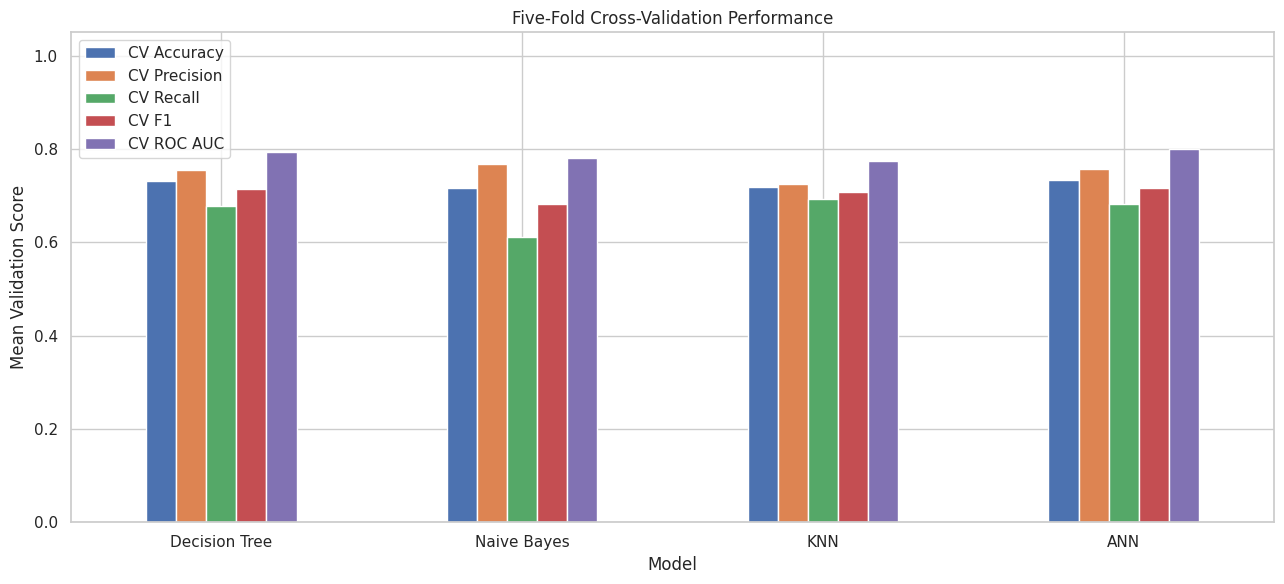

In [30]:
cv_results.set_index('Model')[
    [
        'CV Accuracy',
        'CV Precision',
        'CV Recall',
        'CV F1',
        'CV ROC AUC'
    ]
].plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title("Five-Fold Cross-Validation Performance")
plt.ylabel("Mean Validation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT / 'cross_validation_comparison.png',
    dpi=150
)

plt.show()

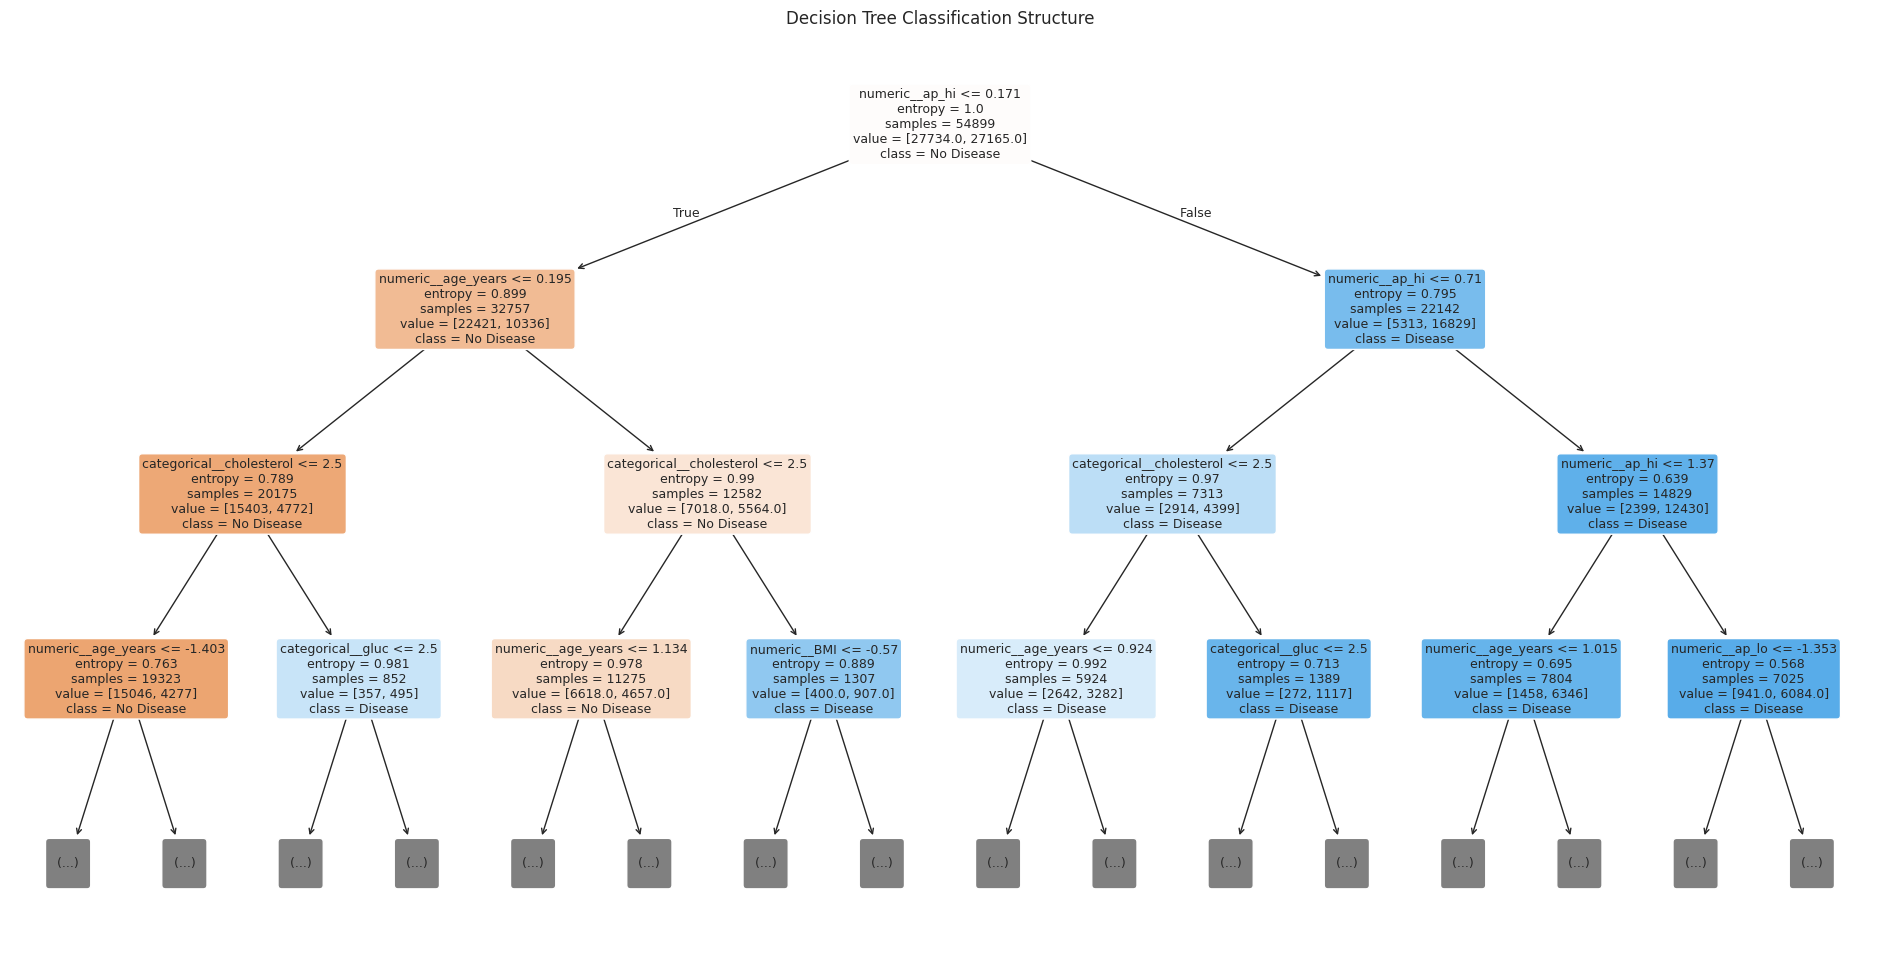

In [31]:
tree = dt_model.named_steps['classifier']

encoded_features = (
    dt_model.named_steps['preprocessing']
    .get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    tree,
    feature_names=encoded_features,
    class_names=[
        'No Disease',
        'Disease'
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Classification Structure")

plt.savefig(
    OUTPUT / 'decision_tree_structure.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

,Feature,Importance
3,numeric__ap_hi,0.711787
0,numeric__age_years,0.136474
8,categorical__cholesterol,0.073997
5,numeric__BMI,0.027826
2,numeric__weight,0.013248
9,categorical__gluc,0.008125
12,categorical__active,0.008037
1,numeric__height,0.008020
4,numeric__ap_lo,0.007706
6,numeric__PulsePressure,0.001948


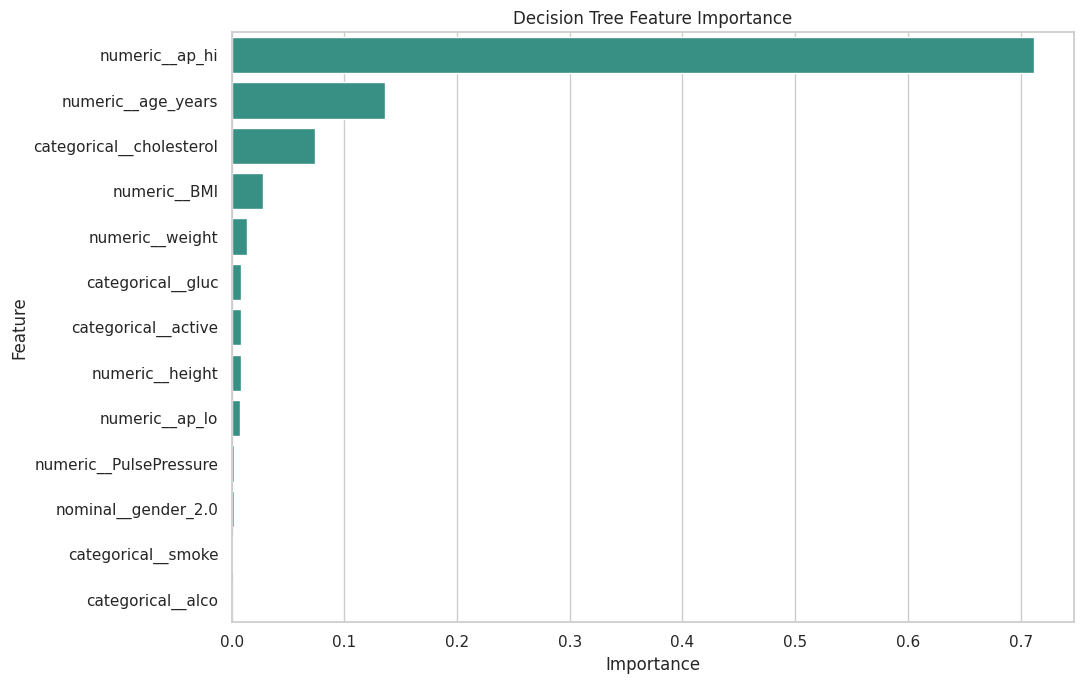

In [32]:
tree_importance = pd.DataFrame({
    'Feature': encoded_features,
    'Importance': tree.feature_importances_
})

tree_importance = tree_importance.sort_values(
    'Importance',
    ascending=False
)

display(tree_importance)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=tree_importance,
    x='Importance',
    y='Feature',
    color='#2A9D8F'
)

plt.title("Decision Tree Feature Importance")
plt.tight_layout()

plt.savefig(
    OUTPUT / 'decision_tree_importance.png',
    dpi=150
)

plt.show()

,Feature,Importance,Std
3,ap_hi,0.0349,0.0087
5,cholesterol,0.0323,0.0074
10,age_years,0.0310,0.0061
4,ap_lo,0.0308,0.0045
12,PulsePressure,0.0193,0.0057
9,active,0.0039,0.0037
0,gender,0.0018,0.0017
7,smoke,0.0015,0.0006
8,alco,0.0006,0.0011
11,BMI,0.0005,0.0022


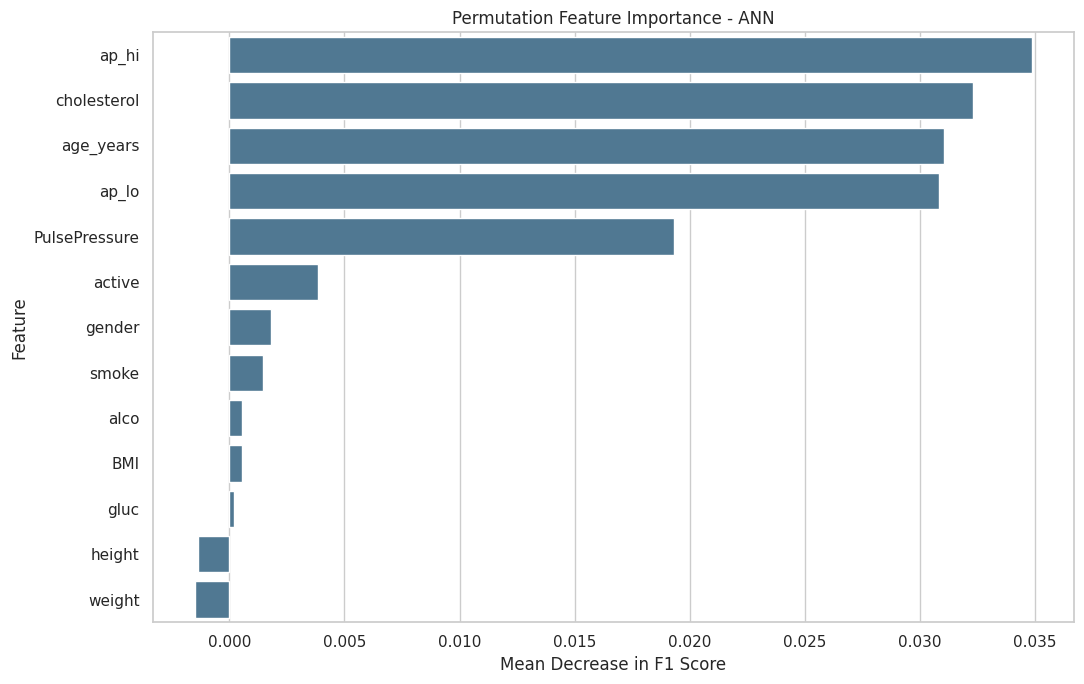

In [33]:
best_model = trained_models[
    best_model_name
]

# Use a reproducible sample for interpretation
X_importance = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

y_importance = y_test.loc[
    X_importance.index
]

perm = permutation_importance(
    best_model,
    X_importance,
    y_importance,
    scoring='f1',
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance = pd.DataFrame({
    'Feature': X_importance.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

display(importance.round(4))

plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    color='#457B9D'
)

plt.title(
    f"Permutation Feature Importance - {best_model_name}"
)

plt.xlabel("Mean Decrease in F1 Score")
plt.tight_layout()

plt.savefig(
    OUTPUT / 'best_model_feature_importance.png',
    dpi=200
)

plt.show()

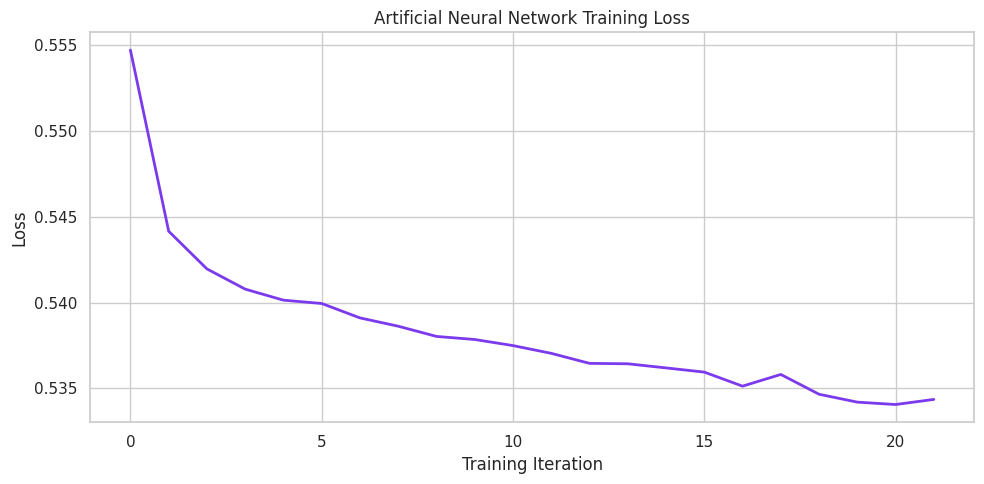

ANN Training Iterations: 22


In [34]:
ann_classifier = ann_model.named_steps[
    'classifier'
]

plt.figure(figsize=(10, 5))

plt.plot(
    ann_classifier.loss_curve_,
    color='#7C3AED',
    linewidth=2
)

plt.title("Artificial Neural Network Training Loss")
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.tight_layout()

plt.savefig(
    OUTPUT / 'ann_training_loss.png',
    dpi=150
)

plt.show()

print(
    "ANN Training Iterations:",
    ann_classifier.n_iter_
)

In [35]:
print("=" * 55)
print("BEST CARDIOVASCULAR CLASSIFICATION MODEL")
print("=" * 55)

print("Selected Algorithm:", best_model_name)

display(
    cv_results[
        cv_results['Model'] == best_model_name
    ].round(4)
)

display(
    results[
        results['Model'] == best_model_name
    ].round(4)
)

BEST CARDIOVASCULAR CLASSIFICATION MODEL
Selected Algorithm: ANN


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC AUC,F1 Std
3,ANN,0.7341,0.7573,0.6816,0.7173,0.8002,0.0028


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time
3,ANN,0.7277,0.7459,0.6818,0.7124,0.7937,7.6973


In [36]:
def predict_cardiovascular_disease(
    age,
    gender,
    height,
    weight,
    systolic_bp,
    diastolic_bp,
    cholesterol,
    glucose,
    smoking,
    alcohol,
    physical_activity
):

    patient = pd.DataFrame([{
        'age_years': age,
        'gender': gender,
        'height': height,
        'weight': weight,
        'ap_hi': systolic_bp,
        'ap_lo': diastolic_bp,
        'cholesterol': cholesterol,
        'gluc': glucose,
        'smoke': smoking,
        'alco': alcohol,
        'active': physical_activity
    }])

    # Validate example input
    for col, (lower, upper) in bounds.items():

        if not patient[col].between(
            lower, upper
        ).all():

            raise ValueError(
                f"Invalid input for {col}"
            )

    for col, allowed in valid_categories.items():

        if not patient[col].isin(allowed).all():

            raise ValueError(
                f"Invalid category for {col}"
            )

    if systolic_bp <= diastolic_bp:

        raise ValueError(
            "Systolic BP must exceed diastolic BP."
        )

    patient = add_features(patient)

    patient = patient[feature_columns]

    prediction = best_model.predict(patient)[0]

    score = best_model.predict_proba(
        patient
    )[0, 1]

    print("=" * 45)
    print("CARDIOVASCULAR CLASSIFICATION SYSTEM")
    print("=" * 45)

    print("Selected Model:", best_model_name)
    print("Age:", age)
    print("BMI:", round(patient['BMI'].iloc[0], 2))

    print(f"Disease Class Score: {score:.2%}")

    if prediction == 1:

        print("Predicted Class: Disease Recorded")

    else:

        print("Predicted Class: No Disease Recorded")

    print(
        "\nEducational model only. "
        "Not a medical diagnosis."
    )

    return prediction, score

In [37]:
# Synthetic patient record for demonstration

predict_cardiovascular_disease(
    age=58,
    gender=2,
    height=170,
    weight=85,
    systolic_bp=150,
    diastolic_bp=95,
    cholesterol=3,
    glucose=2,
    smoking=1,
    alcohol=0,
    physical_activity=0
)

CARDIOVASCULAR CLASSIFICATION SYSTEM
Selected Model: ANN
Age: 58
BMI: 29.41
Disease Class Score: 86.72%
Predicted Class: Disease Recorded

Educational model only. Not a medical diagnosis.


(np.int64(1), np.float64(0.8672424962560136))

In [38]:
healthcare_results = []

for name in trained_models:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if tp + fn > 0 else 0
    )

    specificity = (
        tn / (tn + fp)
        if tn + fp > 0 else 0
    )

    healthcare_results.append({
        'Model': name,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'True Positive': tp,
        'True Negative': tn,
        'False Positive': fp,
        'False Negative': fn
    })

healthcare_results = pd.DataFrame(
    healthcare_results
)

display(healthcare_results.round(4))

,Model,Sensitivity,Specificity,True Positive,True Negative,False Positive,False Negative
0,Decision Tree,0.6594,0.7868,4478,5456,1478,2313
1,Naive Bayes,0.6027,0.8114,4093,5626,1308,2698
2,KNN,0.6828,0.7344,4637,5092,1842,2154
3,ANN,0.6818,0.7726,4630,5357,1577,2161


In [39]:
best_accuracy_model = results.loc[
    results['Accuracy'].idxmax(),
    'Model'
]

best_recall_model = results.loc[
    results['Recall'].idxmax(),
    'Model'
]

best_f1_model = results.loc[
    results['F1 Score'].idxmax(),
    'Model'
]

fastest_model = results.loc[
    results['Training Time'].idxmin(),
    'Model'
]

print("=" * 55)
print("FINAL PROJECT SUMMARY")
print("=" * 55)

print("Original Records:", len(df))
print("Cleaned Records:", len(clean))

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Total Input Features:", X.shape[1])

print("Algorithms Implemented:", len(models))

print(
    "Selected Model (CV F1):",
    best_model_name
)

print(
    "Highest Test Accuracy:",
    best_accuracy_model
)

print(
    "Highest Test Recall:",
    best_recall_model
)

print(
    "Highest Test F1 Score:",
    best_f1_model
)

print(
    "Fastest Training Model:",
    fastest_model
)

print(
    "Most Important Feature:",
    importance.iloc[0]['Feature']
)

display(results.round(4))

FINAL PROJECT SUMMARY
Original Records: 70000
Cleaned Records: 68624
Training Records: 54899
Testing Records: 13725
Total Input Features: 13
Algorithms Implemented: 4
Selected Model (CV F1): ANN
Highest Test Accuracy: ANN
Highest Test Recall: KNN
Highest Test F1 Score: ANN
Fastest Training Model: Naive Bayes
Most Important Feature: ap_hi


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time
3,ANN,0.7277,0.7459,0.6818,0.7124,0.7937,7.6973
0,Decision Tree,0.7238,0.7518,0.6594,0.7026,0.7847,0.2868
2,KNN,0.7089,0.7157,0.6828,0.6989,0.7621,0.2017
1,Naive Bayes,0.7081,0.7578,0.6027,0.6714,0.7762,0.0877


In [40]:
# Export cleaned dataset
clean.to_csv(
    OUTPUT / 'cleaned_cardiovascular_data.csv',
    index=False
)

# Export evaluation results
results.to_csv(
    OUTPUT / 'model_evaluation.csv',
    index=False
)

cv_results.to_csv(
    OUTPUT / 'cross_validation_results.csv',
    index=False
)

healthcare_results.to_csv(
    OUTPUT / 'healthcare_metrics.csv',
    index=False
)

importance.to_csv(
    OUTPUT / 'feature_importance.csv',
    index=False
)

tree_importance.to_csv(
    OUTPUT / 'decision_tree_importance.csv',
    index=False
)

outlier_report.to_csv(
    OUTPUT / 'outlier_report.csv',
    index=False
)

# Export test-set predictions
prediction_output = X_test.copy()

prediction_output['Actual_Class'] = y_test

for name in trained_models:

    safe_name = name.lower().replace(' ', '_')

    prediction_output[
        f'{safe_name}_prediction'
    ] = predictions[name]

    prediction_output[
        f'{safe_name}_score'
    ] = probabilities[name]

prediction_output.to_csv(
    OUTPUT / 'patient_predictions.csv',
    index=False
)

# Save all four complete model pipelines
for name, model in trained_models.items():

    filename = (
        name.lower().replace(' ', '_')
        + '_model.pkl'
    )

    joblib.dump(
        model,
        OUTPUT / filename
    )

# Save selected model
joblib.dump(
    {
        'model': best_model,
        'model_name': best_model_name,
        'features': feature_columns
    },
    OUTPUT / 'best_cardiovascular_model.pkl'
)

print("All project files exported successfully!")

for file in sorted(OUTPUT.iterdir()):
    print(file.name)

All project files exported successfully!
__notebook__.ipynb
age_analysis.png
ann_model.pkl
ann_training_loss.png
best_cardiovascular_model.pkl
best_model_feature_importance.png
blood_pressure_analysis.png
cholesterol_glucose_analysis.png
cleaned_cardiovascular_data.csv
confusion_matrices.png
correlation_heatmap.png
cross_validation_comparison.png
cross_validation_results.csv
decision_tree_importance.csv
decision_tree_importance.png
decision_tree_model.pkl
decision_tree_structure.png
disease_distribution.png
feature_importance.csv
healthcare_metrics.csv
knn_model.pkl
lifestyle_analysis.png
missing_values.png
model_comparison.png
model_evaluation.csv
naive_bayes_model.pkl
outlier_analysis.png
outlier_report.csv
patient_predictions.csv
roc_curve_comparison.png


In [41]:
import zipfile

zip_path = (
    OUTPUT /
    'Cardiovascular_Disease_Project_Outputs.zip'
)

with zipfile.ZipFile(
    zip_path,
    'w',
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in OUTPUT.rglob('*'):

        if (
            file.is_file() and
            file.suffix.lower() in [
                '.csv',
                '.png',
                '.pkl'
            ]
        ):

            archive.write(
                file,
                file.relative_to(OUTPUT)
            )

print("Project ZIP created successfully!")
print(zip_path)

Project ZIP created successfully!
/kaggle/working/Cardiovascular_Disease_Project_Outputs.zip


## Conclusion

The AI-Based Cardiovascular Disease Prediction System demonstrates the application of machine learning and neural network classification techniques to healthcare data analysis.

The project implements data preprocessing, missing value handling, outlier analysis, categorical encoding, feature scaling and feature engineering to improve the quality of patient health records.

Four classification algorithms—Decision Tree Induction, Gaussian Naive Bayes, K-Nearest Neighbor and Artificial Neural Network—were implemented and evaluated using a stratified train-test split and five-fold cross-validation.

The comparative analysis considers accuracy, precision, recall, F1 score, ROC-AUC, sensitivity, specificity and confusion matrices. Feature importance analysis provides insight into the patient characteristics associated with model predictions.

The final model is selected based on cross-validation F1 score and incorporated into a conceptual intelligent healthcare classification system.

The system demonstrates the potential of machine learning in healthcare data analysis. However, limitations include dataset representativeness, self-reported lifestyle information, correlated features, possible measurement errors and the absence of independent clinical validation.

Future improvements may include hyperparameter optimization, probability calibration, explainable artificial intelligence, external dataset validation and the development of a clinically evaluated healthcare decision-support interface.

This project is intended for academic and research purposes and should not be used as a substitute for professional medical diagnosis.